# Spotify popularity classification across five data partitions

This notebook extends the first experiment with four new, deterministic partitions.
It requires the original `archive.zip` and the `model_results` folder produced by Notebook 02.
Place both next to this notebook or edit DATA_PATH and PRIOR. Outputs go to stability_results.

The original partition is retained as seed 20261123. New partition seeds are 20261124–20261127.
The two previously validation-selected forest configurations remain fixed: depth 12 / min leaf 20
for version grouping and depth 20 / min leaf 5 for artist independence. Logistic regression also
remains unchanged. The estimator random seed is fixed at 20261123 to focus on partition variation.
Only the decision threshold is chosen anew on each partition's validation subset using maximum F1.
There is no model search or feature revision based on these test results.

The five partitions reuse the same catalogue and may have overlapping test records across runs.
Their standard deviations and ranges describe partition sensitivity, not confidence intervals or
five independent replications. Original hyperparameters were selected on the original validation
set; this is a conditional robustness check, not nested cross-validation or external validation.

## Results from this saved execution

The artist-independent forest has mean test AP **0.1473**, sample SD **0.0076**,
and observed range **0.1412–0.1601** over five partitions. Its mean precision is
**17.0%** and recall **33.2%** at validation-selected thresholds.
The version-grouped forest has mean AP **0.1749**, SD **0.0068**.
Forest AP exceeds logistic AP in all five partitions under each protocol.

This summary describes the saved run. When changing inputs, inspect the newly computed outputs.
The partitions share one catalogue, so these spreads are not confidence intervals or external validation.
All eight new experiment prediction files, their source labels, split memberships and metrics were independently
rechecked before delivery; forbidden group and artist intersections were zero.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from functools import lru_cache
from itertools import combinations
import ast, hashlib, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning

PRIOR=Path('model_results')
OUT=Path('stability_results'); OUT.mkdir(exist_ok=True)
DATA_PATH=next((p for p in [Path('archive.zip'),Path.home()/'Downloads'/'archive.zip'] if p.exists()),Path('archive.zip'))
ORIGINAL_SEED=20261123
NEW_SEEDS=[20261124,20261125,20261126,20261127]
MODEL_SEED=20261123
metadata=json.loads((PRIOR/'experiment_metadata.json').read_text())
FEATURES=metadata['features']
AUDIO=FEATURES[:9]
CONTINUOUS=[c for c in AUDIO if c!='tempo']+['duration_ms']
with ZipFile(DATA_PATH) as z:
    digest=hashlib.sha256()
    with z.open('tracks.csv') as f:
        for block in iter(lambda:f.read(1024*1024),b''): digest.update(block)
    with z.open('tracks.csv') as f: raw=pd.read_csv(f,keep_default_na=False)
assert digest.hexdigest()==metadata['dataset_sha256']
manifest=pd.read_csv(PRIOR/'split_manifest.csv.gz')
assert np.array_equal(manifest.id.to_numpy(),raw.id.to_numpy())
assert raw.id.is_unique
groups=manifest.version_group.to_numpy()
X=raw[FEATURES].copy()
y=raw.popularity.ge(60).astype('int8').to_numpy()
@lru_cache(maxsize=None)
def ids(s):
    values=ast.literal_eval(s)
    assert values and all(isinstance(v,str) and v.strip() for v in values)
    return tuple(sorted(set(values)))
artists=raw.id_artists.map(ids)
@lru_cache(maxsize=None)
def partition(key,namespace,seed):
    h=hashlib.blake2b(f'{seed}|{namespace}|{key}'.encode(),digest_size=8).digest()
    u=int.from_bytes(h,'big')/2**64
    return 'train' if u<.6 else ('validation' if u<.8 else 'test')
def create_splits(seed):
    a=np.array([partition(g,'version',seed) for g in groups],dtype=object)
    b=[]
    for values in artists:
        parts={partition(v,'artist',seed) for v in values}
        b.append(next(iter(parts)) if len(parts)==1 else 'excluded_cross_artist')
    b=np.array(b,dtype=object)
    keep=np.isin(b,['train','validation','test'])
    overlap=pd.DataFrame({'group':groups[keep],'part':b[keep]}).groupby('group').part.nunique()
    crossing=set(overlap.loc[overlap>1].index)
    b[keep & pd.Series(groups).isin(crossing).to_numpy()]='excluded_cross_version'
    return {'version_grouped':a,'artist_disjoint':b}
original=create_splits(ORIGINAL_SEED)
for experiment,parts in original.items():
    assert np.array_equal(parts,manifest[f'{experiment}_split'].to_numpy())
print('Source hash, record order, and original split reproduction verified.')

Source hash, record order, and original split reproduction verified.


## Fixed pipelines and original results

Preprocessing matches Notebook 02 exactly. Numeric statistics are fitted on each training subset.
Tempo zero is treated as missing with a training median and indicator. Time signature zero is
encoded as an unknown category. All 13 source columns retain original units, including milliseconds.
The constant baseline uses the training positive rate as its score and threshold 0.5.
AP is average_precision_score, not trapezoidal PR-AUC.

In [2]:
def preprocessing():
    return ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())]),CONTINUOUS),
        ('tempo',Pipeline([('impute',SimpleImputer(missing_values=0,strategy='median',add_indicator=True)),('scale',StandardScaler())]),['tempo']),
        ('categorical',Pipeline([('impute',SimpleImputer(strategy='constant',fill_value=-1)),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),['key','mode']),
        ('time_signature',Pipeline([('impute',SimpleImputer(missing_values=0,strategy='constant',fill_value=-1)),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),['time_signature'])
    ],remainder='drop')
def models(experiment):
    depth,leaf=(12,20) if experiment=='version_grouped' else (20,5)
    assert metadata['decisions'][experiment]['selected_forest']==f'forest_depth{depth}'
    return {
        'logistic_regression':LogisticRegression(C=1,class_weight='balanced',max_iter=1500,random_state=MODEL_SEED),
        'random_forest':RandomForestClassifier(n_estimators=160,max_depth=depth,min_samples_leaf=leaf,
            max_samples=.65,class_weight='balanced_subsample',max_features='sqrt',n_jobs=4,random_state=MODEL_SEED)
    }
def best_threshold(labels,scores):
    p,r,t=precision_recall_curve(labels,scores)
    f=np.divide(2*p[:-1]*r[:-1],p[:-1]+r[:-1],out=np.zeros(len(t)),where=(p[:-1]+r[:-1])>0)
    j=np.flatnonzero(np.isclose(f,f.max(),rtol=0,atol=1e-12))[-1]
    return float(t[j]),float(f[j])
def evaluate(seed,experiment,name,rule,threshold,labels,scores):
    pred=scores>=threshold
    tn,fp,fn,tp=confusion_matrix(labels,pred,labels=[0,1]).ravel()
    return {'seed':seed,'experiment':experiment,'model':name,'threshold_rule':rule,'threshold':threshold,
        'test_rows':len(labels),'test_positives':int(labels.sum()),'test_positive_rate':float(labels.mean()),
        'ap':float(average_precision_score(labels,scores)),
        'precision':float(precision_score(labels,pred,zero_division=0)),
        'recall':float(recall_score(labels,pred,zero_division=0)),
        'f1':float(f1_score(labels,pred,zero_division=0)),
        'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
prior=pd.read_json(PRIOR/'test_results.json')
records=[]
for _,row in prior.iterrows():
    r=row.to_dict(); r.pop('roc_auc',None)
    r['seed']=ORIGINAL_SEED; r['test_positives']=int(r['tp']+r['fn'])
    if r['model'].startswith('forest_'):r['model']='random_forest'
    records.append(r)
split_records=pd.read_json(PRIOR/'split_summary.json').assign(seed=ORIGINAL_SEED).to_dict('records')
overlap_records=pd.read_json(PRIOR/'overlap_checks.json').assign(seed=ORIGINAL_SEED).to_dict('records')
validation=[]
print('Original results imported:',len(records),'rows')

Original results imported: 10 rows


## Four additional partitions

For each partition, thresholds are frozen before computing that partition's test scores.
All version-group intersections must be empty. In the artist-independent experiment, every artist
intersection must also be empty, including collaborators. Excluded records and their target rates
are retained in the audit. No record is removed merely because its label is difficult to predict.

In [3]:
new_manifest=pd.DataFrame({'id':raw.id})
for seed in NEW_SEEDS:
    print('Starting partition seed',seed,flush=True)
    generated=create_splits(seed)
    for experiment,parts in generated.items():
        new_manifest[f'{experiment}_{seed}']=parts
        idx={p:np.flatnonzero(parts==p) for p in ['train','validation','test']}
        aset={p:{a for values in artists.iloc[rows] for a in values} for p,rows in idx.items()}
        for a,b in combinations(idx,2):
            gv=len(set(groups[idx[a]]) & set(groups[idx[b]]))
            ga=len(aset[a] & aset[b])
            assert gv==0
            if experiment=='artist_disjoint':assert ga==0
            overlap_records.append({'seed':seed,'experiment':experiment,'pair':f'{a}/{b}',
                                     'shared_version_groups':gv,'shared_artists':ga})
        for part in pd.unique(parts):
            rows=np.flatnonzero(parts==part)
            split_records.append({'seed':seed,'experiment':experiment,'partition':part,'rows':len(rows),
                'positives':int(y[rows].sum()),'positive_rate':float(y[rows].mean()),
                'multi_artist_rate':float(artists.iloc[rows].map(len).gt(1).mean())})
        train,val,test=idx['train'],idx['validation'],idx['test']
        fitted={}
        for name,estimator in models(experiment).items():
            started=time.monotonic()
            model=Pipeline([('preprocess',preprocessing()),('classifier',estimator)])
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always',ConvergenceWarning)
                model.fit(X.iloc[train],y[train])
            assert not any(issubclass(w.category,ConvergenceWarning) for w in caught)
            score=model.predict_proba(X.iloc[val])[:,1]
            threshold,vf1=best_threshold(y[val],score)
            fitted[name]=(model,threshold)
            validation.append({'seed':seed,'experiment':experiment,'model':name,'threshold':threshold,
                'validation_ap':float(average_precision_score(y[val],score)), 'validation_f1':vf1})
            print(seed,experiment,name,'validation AP',round(validation[-1]['validation_ap'],5),
                  'seconds',round(time.monotonic()-started,1),flush=True)
        (OUT/'validation_decisions.json').write_text(json.dumps(validation,indent=2))
        baseline=np.full(len(test),y[train].mean())
        records.append(evaluate(seed,experiment,'constant_baseline','default_0.5',.5,y[test],baseline))
        predictions=pd.DataFrame({'id':raw.id.iloc[test].to_numpy(),'high_popularity':y[test]})
        for name,(model,threshold) in fitted.items():
            scores=model.predict_proba(X.iloc[test])[:,1]
            predictions[name+'_score']=scores
            for rule,t in [('default_0.5',.5),('validation_max_f1',threshold)]:
                records.append(evaluate(seed,experiment,name,rule,t,y[test],scores))
            print(seed,experiment,name,'test AP',round(records[-1]['ap'],5),flush=True)
        predictions.to_csv(OUT/f'predictions_{experiment}_{seed}.csv.gz',index=False,compression='gzip')
        pd.DataFrame(records).to_json(OUT/'all_test_results.json',orient='records',indent=2)
        del fitted
new_manifest.to_csv(OUT/'additional_split_manifest.csv.gz',index=False,compression='gzip')
results=pd.DataFrame(records)
split_audit=pd.DataFrame(split_records)
overlap_audit=pd.DataFrame(overlap_records)
split_audit.to_json(OUT/'all_split_counts.json',orient='records',indent=2)
overlap_audit.to_json(OUT/'all_overlap_checks.json',orient='records',indent=2)
assert len(results)==50
assert (results[['tn','fp','fn','tp']].sum(axis=1)==results.test_rows).all()
assert (results.tp+results.fn==results.test_positives).all()
assert overlap_audit.shared_version_groups.eq(0).all()
assert overlap_audit.loc[overlap_audit.experiment.eq('artist_disjoint'),'shared_artists'].eq(0).all()
display(results.loc[results.threshold_rule.eq('validation_max_f1')].round(5))

Starting partition seed 20261124
20261124 version_grouped logistic_regression validation AP 0.14672 seconds 0.9
20261124 version_grouped random_forest validation AP 0.16855 seconds 17.3
20261124 version_grouped logistic_regression test AP 0.14605
20261124 version_grouped random_forest test AP 0.16516
20261124 artist_disjoint logistic_regression validation AP 0.11507 seconds 0.8
20261124 artist_disjoint random_forest validation AP 0.14029 seconds 20.4
20261124 artist_disjoint logistic_regression test AP 0.13834
20261124 artist_disjoint random_forest test AP 0.1479
Starting partition seed 20261125
20261125 version_grouped logistic_regression validation AP 0.14051 seconds 0.8
20261125 version_grouped random_forest validation AP 0.16723 seconds 17.6
20261125 version_grouped logistic_regression test AP 0.15811
20261125 version_grouped random_forest test AP 0.18404
20261125 artist_disjoint logistic_regression validation AP 0.13253 seconds 0.8
20261125 artist_disjoint random_forest validation

,experiment,model,threshold_rule,threshold,test_rows,test_positive_rate,ap,precision,recall,f1,tn,fp,fn,tp,seed,test_positives
2,version_grouped,logistic_regression,validation_max_f1,0.69791,117017,0.04762,0.15153,0.16524,0.37976,0.23028,100755,10690,3456,2116,20261123,5572
4,version_grouped,random_forest,validation_max_f1,0.65998,117017,0.04762,0.17523,0.20258,0.39465,0.26773,102789,8656,3373,2199,20261123,5572
7,artist_disjoint,logistic_regression,validation_max_f1,0.69532,96654,0.04459,0.13436,0.14830,0.35406,0.20904,83580,8764,2784,1526,20261123,4310
9,artist_disjoint,random_forest,validation_max_f1,0.53432,96654,0.04459,0.16006,0.19534,0.30139,0.23704,86993,5351,3011,1299,20261123,4310
12,version_grouped,logistic_regression,validation_max_f1,0.69805,118185,0.04710,0.14605,0.16026,0.36723,0.22314,101909,10710,3522,2044,20261124,5566
14,version_grouped,random_forest,validation_max_f1,0.66690,118185,0.04710,0.16516,0.19095,0.36094,0.24977,104107,8512,3557,2009,20261124,5566
17,artist_disjoint,logistic_regression,validation_max_f1,0.67367,97304,0.04711,0.13834,0.14686,0.37805,0.21155,82653,10067,2851,1733,20261124,4584
19,artist_disjoint,random_forest,validation_max_f1,0.47566,97304,0.04711,0.14790,0.17228,0.31348,0.22236,85816,6904,3147,1437,20261124,4584
22,version_grouped,logistic_regression,validation_max_f1,0.68619,117033,0.04902,0.15811,0.16723,0.40492,0.23670,99728,11568,3414,2323,20261125,5737
24,version_grouped,random_forest,validation_max_f1,0.65982,117033,0.04902,0.18404,0.20178,0.38626,0.26509,102530,8766,3521,2216,20261125,5737


## Partition sensitivity and interpretation

Means and sample standard deviations below give each partition equal weight. They are not pooled
record-level estimates. AP divided by test prevalence measures improvement over the constant-score
baseline within that partition; it is not the fraction of correctly predicted songs.
Paired forest-minus-logistic differences compare models on the same test partition. Comparisons
between the two split protocols involve different populations and exclusions.

,experiment,model,ap_mean,ap_std,ap_min,ap_max,precision_mean,precision_std,precision_min,precision_max,recall_mean,recall_std,recall_min,recall_max,f1_mean,f1_std,f1_min,f1_max,ap_over_baseline_mean,ap_over_baseline_std,ap_over_baseline_min,ap_over_baseline_max
0,artist_disjoint,constant_baseline,0.04358,0.00236,0.04093,0.04711,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,1.00000,1.00000
1,artist_disjoint,logistic_regression,0.12820,0.00777,0.12067,0.13834,0.13788,0.00896,0.13029,0.14830,0.37042,0.00985,0.35406,0.37825,0.20075,0.00884,0.19290,0.21155,2.94140,0.06582,2.84023,3.01311
2,artist_disjoint,random_forest,0.14729,0.00759,0.14122,0.16006,0.17047,0.01838,0.14879,0.19534,0.33220,0.04954,0.28171,0.40418,0.22289,0.00812,0.21751,0.23704,3.38328,0.16401,3.13950,3.58940
3,version_grouped,constant_baseline,0.04794,0.00073,0.04710,0.04902,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,1.00000,1.00000
4,version_grouped,logistic_regression,0.15138,0.00464,0.14605,0.15811,0.16462,0.00582,0.15782,0.17255,0.38210,0.02267,0.35387,0.40492,0.22984,0.00511,0.22314,0.23670,3.15745,0.05275,3.10106,3.22538
5,version_grouped,random_forest,0.17493,0.00676,0.16516,0.18404,0.19620,0.00859,0.18354,0.20258,0.38507,0.02351,0.36094,0.41863,0.25958,0.00729,0.24977,0.26773,3.64823,0.09011,3.50696,3.75443


model,seed,experiment,constant_baseline,logistic_regression,random_forest,forest_minus_logistic,forest_minus_baseline
0,20261123,artist_disjoint,0.04459,0.13436,0.16006,0.02570,0.11547
1,20261123,version_grouped,0.04762,0.15153,0.17523,0.02370,0.12761
2,20261124,artist_disjoint,0.04711,0.13834,0.14790,0.00957,0.10079
3,20261124,version_grouped,0.04710,0.14605,0.16516,0.01912,0.11807
4,20261125,artist_disjoint,0.04093,0.12215,0.14122,0.01907,0.10030
5,20261125,version_grouped,0.04902,0.15811,0.18404,0.02593,0.13502
6,20261126,artist_disjoint,0.04249,0.12067,0.14230,0.02163,0.09982
7,20261126,version_grouped,0.04771,0.14825,0.17363,0.02538,0.12592
8,20261127,artist_disjoint,0.04279,0.12550,0.14496,0.01947,0.10217
9,20261127,version_grouped,0.04823,0.15297,0.17657,0.02360,0.12833


threshold_rule,seed,experiment,default_0.5,validation_max_f1,tuned_minus_default_f1
0,20261123,artist_disjoint,0.24200,0.23704,-0.00496
1,20261123,version_grouped,0.20583,0.26773,0.06190
2,20261124,artist_disjoint,0.22217,0.22236,0.00019
3,20261124,version_grouped,0.20464,0.24977,0.04513
4,20261125,artist_disjoint,0.21554,0.21857,0.00303
5,20261125,version_grouped,0.21371,0.26509,0.05138
6,20261126,artist_disjoint,0.22238,0.21751,-0.00487
7,20261126,version_grouped,0.20936,0.25519,0.04584
8,20261127,artist_disjoint,0.22275,0.21896,-0.00379
9,20261127,version_grouped,0.20861,0.26015,0.05154


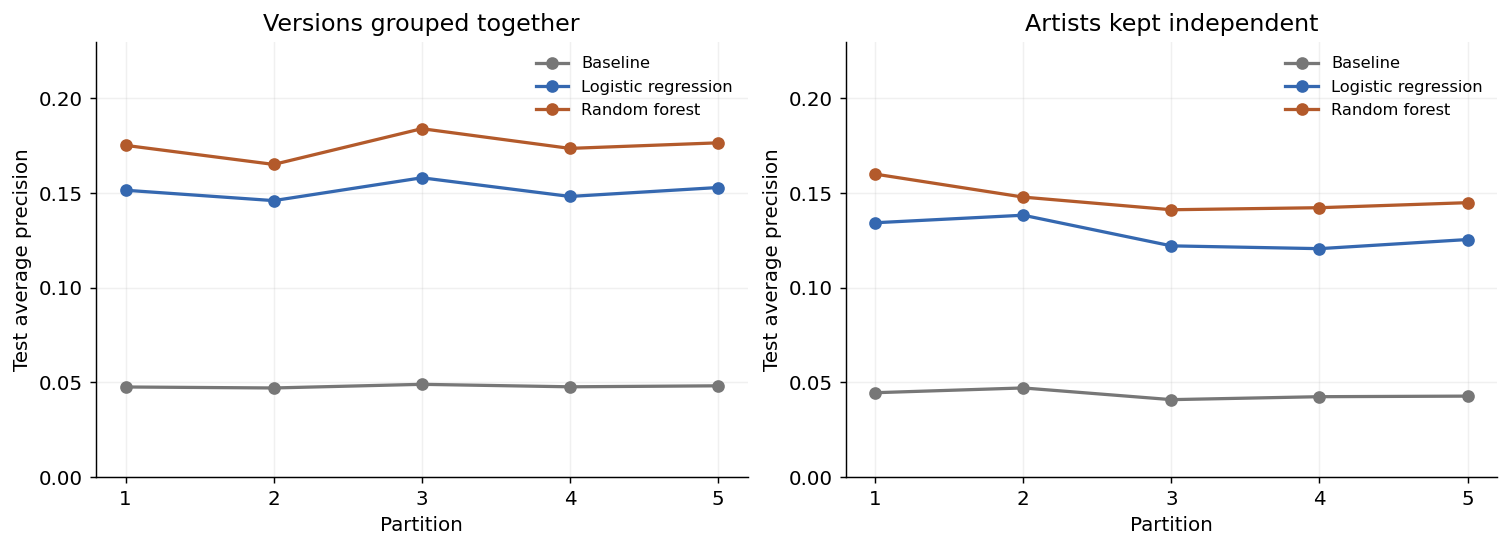

Completed all five partitions. No model changes were made from test outcomes.


In [4]:
main=results.loc[results.threshold_rule.eq('validation_max_f1')|results.model.eq('constant_baseline')].copy()
main['ap_over_baseline']=main.ap/main.test_positive_rate
summary=main.groupby(['experiment','model'])[['ap','precision','recall','f1','ap_over_baseline']].agg(['mean','std','min','max'])
summary.columns=['_'.join(c) for c in summary.columns]
summary=summary.reset_index()
display(summary.round(5))
summary.to_json(OUT/'stability_summary.json',orient='records',indent=2)
paired=main.pivot(index=['seed','experiment'],columns='model',values='ap').reset_index()
paired['forest_minus_logistic']=paired.random_forest-paired.logistic_regression
paired['forest_minus_baseline']=paired.random_forest-paired.constant_baseline
display(paired.round(5))
paired.to_json(OUT/'paired_ap_differences.json',orient='records',indent=2)
rf_thresholds=results.loc[results.model.eq('random_forest')].pivot(index=['seed','experiment'],columns='threshold_rule',values='f1').reset_index()
rf_thresholds['tuned_minus_default_f1']=rf_thresholds.validation_max_f1-rf_thresholds['default_0.5']
display(rf_thresholds.round(5))
rf_thresholds.to_json(OUT/'forest_threshold_comparison.json',orient='records',indent=2)
protocol={'source_sha256':digest.hexdigest(),'partition_seeds':[ORIGINAL_SEED]+NEW_SEEDS,
          'model_seed':MODEL_SEED,'target_threshold':60,'new_hyperparameter_search':False,
          'scope':'conditional repeated holdout on one catalogue; not independent external validation',
          'summary':'equal-weight mean, sample standard deviation, minimum and maximum across five partitions',
          'original_model_configurations':metadata['decisions']}
(OUT/'protocol.json').write_text(json.dumps(protocol,indent=2))

plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(11.5,4.1),layout='constrained')
names={'constant_baseline':'Baseline','logistic_regression':'Logistic regression','random_forest':'Random forest'}
colors={'constant_baseline':'#777777','logistic_regression':'#3568b0','random_forest':'#b35a2b'}
titles={'version_grouped':'Versions grouped together','artist_disjoint':'Artists kept independent'}
for ax,experiment in zip(axes,['version_grouped','artist_disjoint']):
    for model in names:
        d=main.loc[main.experiment.eq(experiment)&main.model.eq(model)].sort_values('seed')
        ax.plot(range(1,6),d.ap,marker='o',color=colors[model],lw=1.8,label=names[model])
    ax.set(title=titles[experiment],xlabel='Partition',ylabel='Test average precision',xticks=range(1,6),ylim=(0,.23))
    ax.grid(alpha=.18); ax.legend(loc='upper right',frameon=False,fontsize=9)
fig.savefig(OUT/'stability_overview.png',dpi=200,bbox_inches='tight')
display(fig);plt.close(fig)
print('Completed all five partitions. No model changes were made from test outcomes.')

## Descriptive training statistics used in the report

These post-fit summaries use the original version-grouped training subset only. They do not
select features or change any model. Loudness is measured in decibels; tempo in beats per minute;
the other listed scores are on a zero-to-one scale. Original zero tempo values are retained here.

In [5]:
training=raw.loc[manifest.version_grouped_split.eq('train')].copy()
training['high_popularity']=training.popularity.ge(60)
descriptive=[]
for feature in ['loudness','acousticness','energy','danceability','valence','tempo']:
    descriptive.append({'feature':feature,
        'ordinary_median':float(training.loc[~training.high_popularity,feature].median()),
        'popular_median':float(training.loc[training.high_popularity,feature].median())})
descriptive_table=pd.DataFrame(descriptive)
display(descriptive_table)
descriptive_table.to_json(OUT/'training_descriptive_stats.json',orient='records',indent=2)

,feature,ordinary_median,popular_median
0,loudness,-9.431,-6.383
1,acousticness,0.441,0.174
2,energy,0.541,0.666
3,danceability,0.574,0.646
4,valence,0.567,0.531
5,tempo,117.110,120.053
